# ITSM Machine Learning Project

### Project Objective

* ABC Tech receives a large number of IT incidents/tickets.
* The objective of this project is to use Machine Learning to predict high-priority ITSM tickets.
* The model will help identify tickets that may require faster attention and support better incident management.

### Business Goal
- Predict high-priority tickets.
- Reduce delay in handling important incidents.
- Support better incident management.
- Help the IT team prioritize tickets automatically.

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

In [20]:
df = pd.read_csv("itsm_data.csv")

In [21]:
df

,CI_Name,CI_Cat,CI_Subcat,WBS,Incident_ID,Status,Impact,Urgency,Priority,number_cnt,...,Reopen_Time,Resolved_Time,Close_Time,Handle_Time_hrs,Closure_Code,No_of_Related_Interactions,Related_Interaction,No_of_Related_Incidents,No_of_Related_Changes,Related_Change
0,SUB000508,subapplication,Web Based Application,WBS000162,IM0000004,Closed,4,4,4.0,0.601292,...,NaN,04-11-2013 13:50,04-11-2013 13:51,"3,87,16,91,111",Other,1.0,SD0000007,2.0,NaN,NaN
1,WBA000124,application,Web Based Application,WBS000088,IM0000005,Closed,3,3,3.0,0.415050,...,02-12-2013 12:31,02-12-2013 12:36,02-12-2013 12:36,"4,35,47,86,389",Software,1.0,SD0000011,1.0,NaN,NaN
2,DTA000024,application,Desktop Application,WBS000092,IM0000006,Closed,NS,3,NaN,0.517551,...,NaN,13-01-2014 15:12,13-01-2014 15:13,"4,84,31,19,444",No error - works as designed,1.0,SD0000017,NaN,NaN,NaN
3,WBA000124,application,Web Based Application,WBS000088,IM0000011,Closed,4,4,4.0,0.642927,...,NaN,14-11-2013 09:31,14-11-2013 09:31,"4,32,18,33,333",Operator error,1.0,SD0000025,NaN,NaN,NaN
4,WBA000124,application,Web Based Application,WBS000088,IM0000012,Closed,4,4,4.0,0.345258,...,NaN,08-11-2013 13:55,08-11-2013 13:55,"3,38,39,03,333",Other,1.0,SD0000029,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
46601,SBA000464,application,Server Based Application,WBS000073,IM0047053,Closed,4,4,4.0,0.231896,...,NaN,31-03-2014 16:29,31-03-2014 16:29,"0,095",Other,1.0,SD0147021,NaN,NaN,NaN
46602,SBA000461,application,Server Based Application,WBS000073,IM0047054,Closed,4,4,4.0,0.805153,...,NaN,31-03-2014 15:29,31-03-2014 15:29,"0,428333333",User error,1.0,SD0146967,NaN,NaN,NaN
46603,LAP000019,computer,Laptop,WBS000091,IM0047055,Closed,5,5,5.0,0.917466,...,NaN,31-03-2014 15:32,31-03-2014 15:32,"0,071666667",Hardware,1.0,SD0146982,NaN,NaN,NaN
46604,WBA000058,application,Web Based Application,WBS000073,IM0047056,Closed,4,4,4.0,0.701278,...,NaN,31-03-2014 15:42,31-03-2014 15:42,"0,116944444",Software,1.0,SD0146986,NaN,NaN,NaN


In [22]:
df.head()

,CI_Name,CI_Cat,CI_Subcat,WBS,Incident_ID,Status,Impact,Urgency,Priority,number_cnt,...,Reopen_Time,Resolved_Time,Close_Time,Handle_Time_hrs,Closure_Code,No_of_Related_Interactions,Related_Interaction,No_of_Related_Incidents,No_of_Related_Changes,Related_Change
0,SUB000508,subapplication,Web Based Application,WBS000162,IM0000004,Closed,4,4,4.0,0.601292,...,NaN,04-11-2013 13:50,04-11-2013 13:51,"3,87,16,91,111",Other,1.0,SD0000007,2.0,NaN,NaN
1,WBA000124,application,Web Based Application,WBS000088,IM0000005,Closed,3,3,3.0,0.415050,...,02-12-2013 12:31,02-12-2013 12:36,02-12-2013 12:36,"4,35,47,86,389",Software,1.0,SD0000011,1.0,NaN,NaN
2,DTA000024,application,Desktop Application,WBS000092,IM0000006,Closed,NS,3,NaN,0.517551,...,NaN,13-01-2014 15:12,13-01-2014 15:13,"4,84,31,19,444",No error - works as designed,1.0,SD0000017,NaN,NaN,NaN
3,WBA000124,application,Web Based Application,WBS000088,IM0000011,Closed,4,4,4.0,0.642927,...,NaN,14-11-2013 09:31,14-11-2013 09:31,"4,32,18,33,333",Operator error,1.0,SD0000025,NaN,NaN,NaN
4,WBA000124,application,Web Based Application,WBS000088,IM0000012,Closed,4,4,4.0,0.345258,...,NaN,08-11-2013 13:55,08-11-2013 13:55,"3,38,39,03,333",Other,1.0,SD0000029,NaN,NaN,NaN


In [23]:
df.shape

(46606, 25)

In [24]:
# Missing values: count and percentage for each column
missing_summary = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df) * 100).round(2)
})
missing_summary = missing_summary[missing_summary["Missing Values"] > 0].sort_values(
    "Missing Percentage", ascending=False
)
print("Columns containing missing values:")
display(missing_summary)
print("\nTotal missing values in original data:", df.isnull().sum().sum())

Columns containing missing values:


,Missing Values,Missing Percentage
No_of_Related_Changes,46046,98.80
Related_Change,46046,98.80
No_of_Related_Incidents,45384,97.38
Reopen_Time,44322,95.10
Resolved_Time,1780,3.82
Priority,1380,2.96
Closure_Code,460,0.99
CI_Cat,111,0.24
CI_Subcat,111,0.24
No_of_Related_Interactions,114,0.24



Total missing values in original data: 185756


In [25]:
df.duplicated().sum()

np.int64(0)

In [26]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 46606 entries, 0 to 46605
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   CI_Name                     46606 non-null  object 
 1   CI_Cat                      46495 non-null  object 
 2   CI_Subcat                   46495 non-null  object 
 3   WBS                         46606 non-null  object 
 4   Incident_ID                 46606 non-null  object 
 5   Status                      46606 non-null  object 
 6   Impact                      46606 non-null  object 
 7   Urgency                     46606 non-null  object 
 8   Priority                    45226 non-null  float64
 9   number_cnt                  46606 non-null  float64
 10  Category                    46606 non-null  object 
 11  KB_number                   46606 non-null  object 
 12  Alert_Status                46606 non-null  object 
 13  No_of_Reassignments         466

In [27]:
df.describe()

,Priority,number_cnt,No_of_Reassignments,No_of_Related_Interactions,No_of_Related_Incidents,No_of_Related_Changes
count,45226.000000,46606.000000,46605.000000,46492.000000,1222.000000,560.000000
mean,4.215805,0.499658,1.131831,1.149897,1.669394,1.058929
std,0.705624,0.288634,2.269774,2.556338,3.339687,0.403596
min,1.000000,0.000023,0.000000,1.000000,1.000000,1.000000
25%,4.000000,0.248213,0.000000,1.000000,1.000000,1.000000
50%,4.000000,0.500269,0.000000,1.000000,1.000000,1.000000
75%,5.000000,0.749094,2.000000,1.000000,1.000000,1.000000
max,5.000000,0.999997,46.000000,370.000000,63.000000,9.000000


In [28]:
df.describe(include="object")

,CI_Name,CI_Cat,CI_Subcat,WBS,Incident_ID,Status,Impact,Urgency,Category,KB_number,Alert_Status,Open_Time,Reopen_Time,Resolved_Time,Close_Time,Handle_Time_hrs,Closure_Code,Related_Interaction,Related_Change
count,46606,46495,46495,46606,46606,46606,46606,46606,46606,46606,46606,46606,2284,44826,46606,46605,46146,46606,560
unique,3019,12,64,274,46606,2,6,11,4,1825,1,34636,2244,33627,34528,30638,14,43060,232
top,SUB000456,application,Server Based Application,WBS000073,IM0000004,Closed,4,4,incident,KM0001106,closed,24-03-2014 08:54,29-10-2013 15:03,10-10-2013 12:53,02-10-2013 15:20,0,Other,#MULTIVALUE,C00003013
freq,3050,32900,18811,13342,1,46597,22556,15526,37748,1106,46606,7,2,7,21,236,16470,3434,110


In [29]:
df.nunique()

CI_Name                        3019
CI_Cat                           12
CI_Subcat                        64
WBS                             274
Incident_ID                   46606
Status                            2
Impact                            6
Urgency                          11
Priority                          5
number_cnt                    46606
Category                          4
KB_number                      1825
Alert_Status                      1
No_of_Reassignments              41
Open_Time                     34636
Reopen_Time                    2244
Resolved_Time                 33627
Close_Time                    34528
Handle_Time_hrs               30638
Closure_Code                     14
No_of_Related_Interactions       49
Related_Interaction           43060
No_of_Related_Incidents          24
No_of_Related_Changes             4
Related_Change                  232
dtype: int64

## Univariate Analysis

Univariate analysis studies one variable at a time. It helps us understand the distribution of numerical and categorical columns before model building.

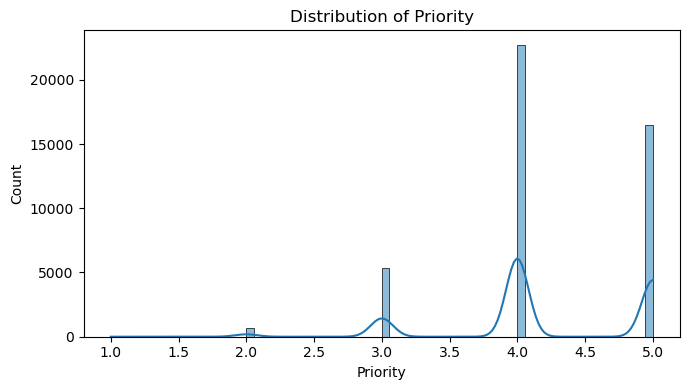

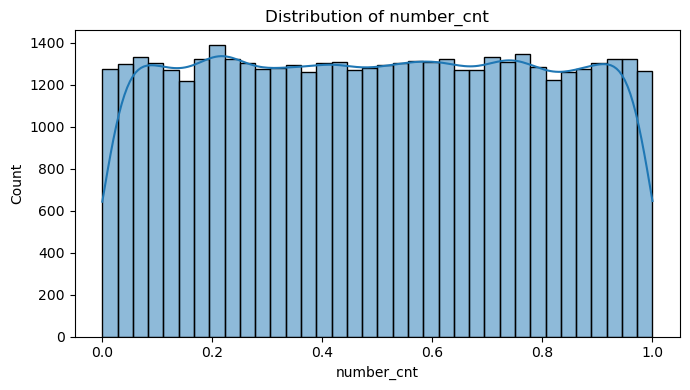

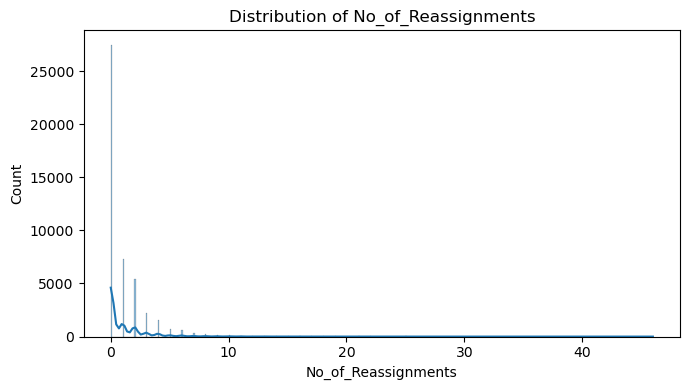

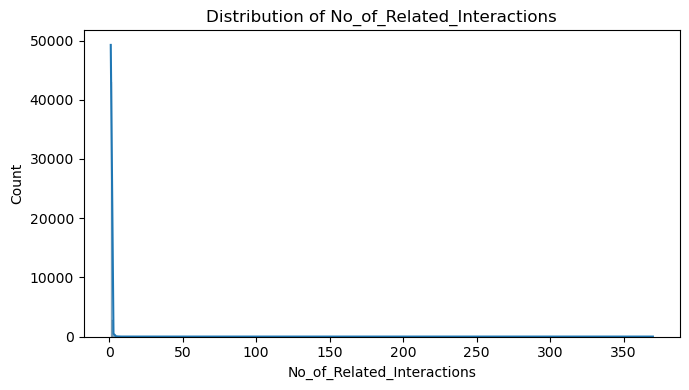

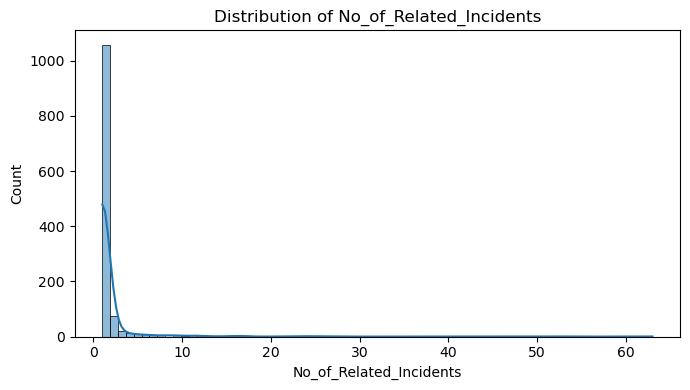

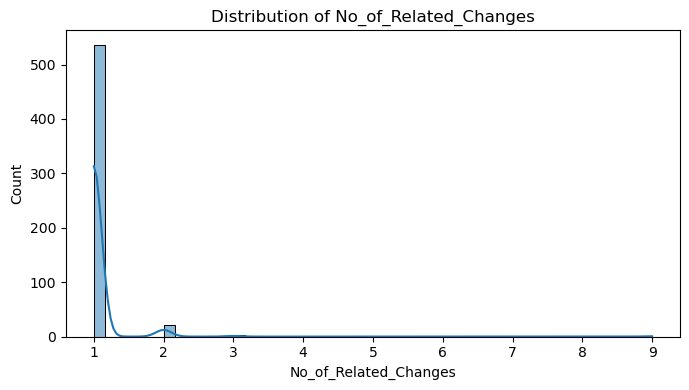

Top values in CI_Name:
CI_Name
SUB000456    3050
SBA000263    2176
SBA000607    1743
SBA000462    1698
WBA000058    1614
WBA000133    1453
SUB000113    1100
WBA000011     945
WBA000144     909
DTA000616     851
Name: count, dtype: int64
--------------------------------------------------
Top values in CI_Cat:
CI_Cat
application          32900
subapplication        7782
computer              3643
storage                703
hardware               442
software               333
database               214
displaydevice          212
officeelectronics      152
NaN                    111
Name: count, dtype: int64
--------------------------------------------------
Top values in CI_Subcat:
CI_Subcat
Server Based Application    18811
Web Based Application       15311
Desktop Application          3876
Laptop                       1921
SAP                          1199
Banking Device                916
Citrix                        767
SAN                           549
Client Based Application     

In [31]:
# Univariate analysis of numerical columns
numeric_columns = df.select_dtypes(include=np.number).columns

for col in numeric_columns:
    plt.figure(figsize=(7, 4))
    sns.histplot(data=df, x=col, kde=True)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()

# Univariate analysis of categorical columns (top 10 values)
categorical_columns = df.select_dtypes(include=["object", "category"]).columns

for col in categorical_columns:
    print(f"Top values in {col}:")
    print(df[col].value_counts(dropna=False).head(10))
    print("-" * 50)


### Priority Distribution

In [33]:
print(df["Priority"].value_counts().sort_index())

Priority
1.0        3
2.0      697
3.0     5323
4.0    22717
5.0    16486
Name: count, dtype: int64


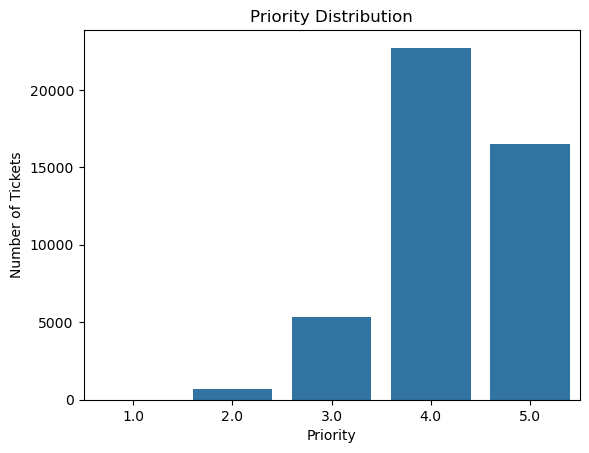

In [34]:
sns.countplot(x="Priority", data=df)
plt.title("Priority Distribution")
plt.xlabel("Priority")
plt.ylabel("Number of Tickets")
plt.show()

### Status Distribution

In [35]:
print(df["Status"].value_counts().head(10))

Status
Closed              46597
Work in progress        9
Name: count, dtype: int64


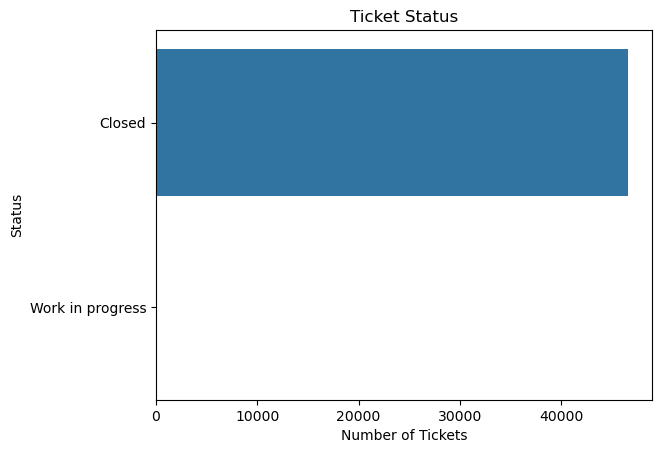

In [36]:
sns.countplot(y="Status", data=df)
plt.title("Ticket Status")
plt.xlabel("Number of Tickets")
plt.ylabel("Status")
plt.show()

### Category Distribution

In [37]:
print(df["Category"].value_counts().head(10))

Category
incident                   37748
request for information     8846
complaint                     11
request for change             1
Name: count, dtype: int64


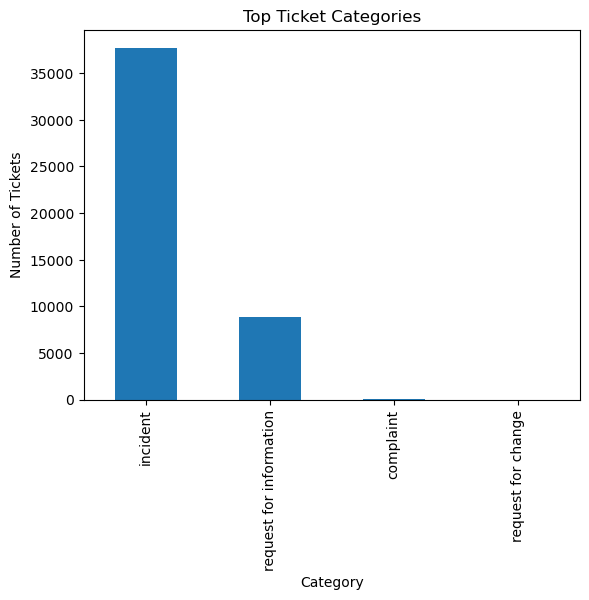

In [38]:
df["Category"].value_counts().head(10).plot(kind="bar")
plt.title("Top Ticket Categories")
plt.xlabel("Category")
plt.ylabel("Number of Tickets")
plt.show()

## Bivariate Analysis

Bivariate analysis compares two variables. Here, we compare `Priority` with selected ticket fields to explore how ticket priority varies by status, category, and numerical ticket-related measures.

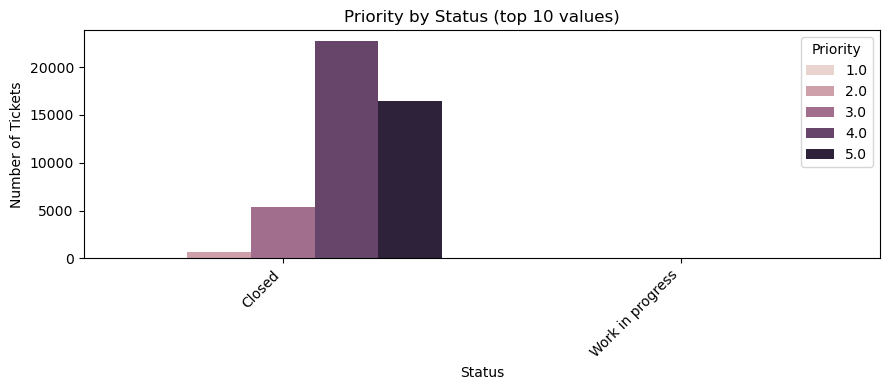

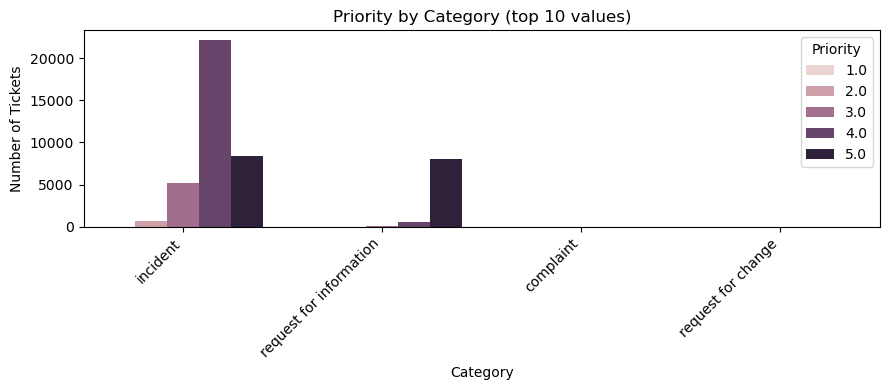

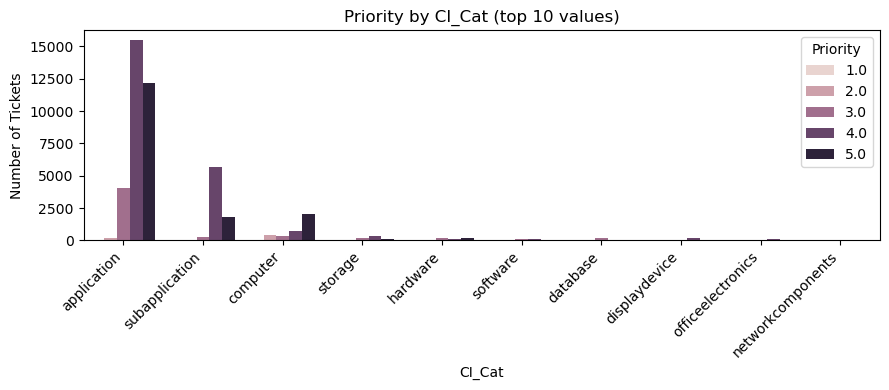

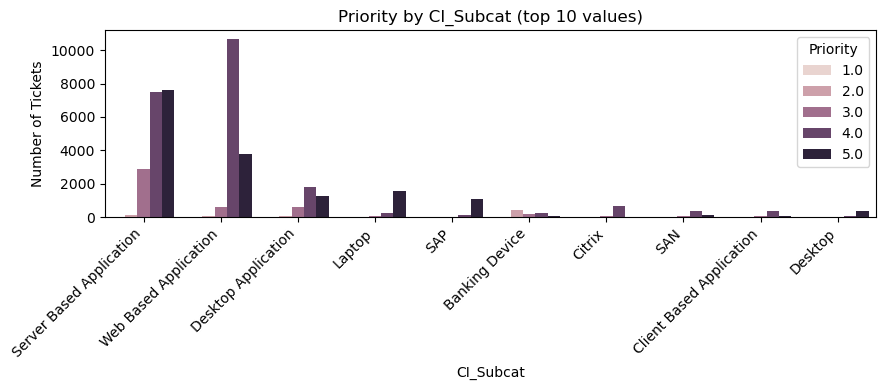

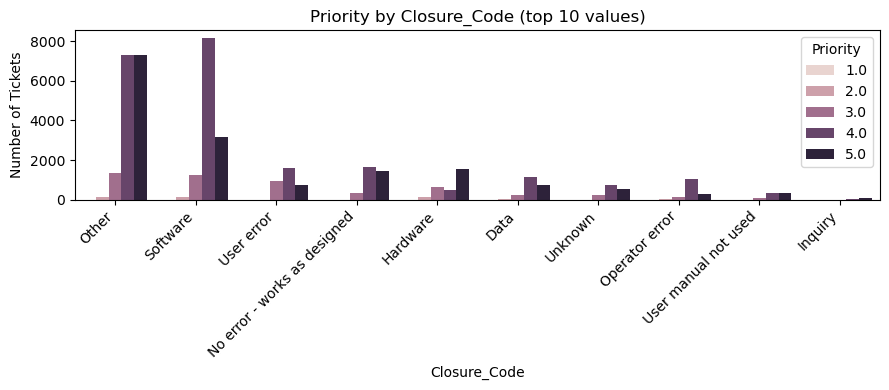

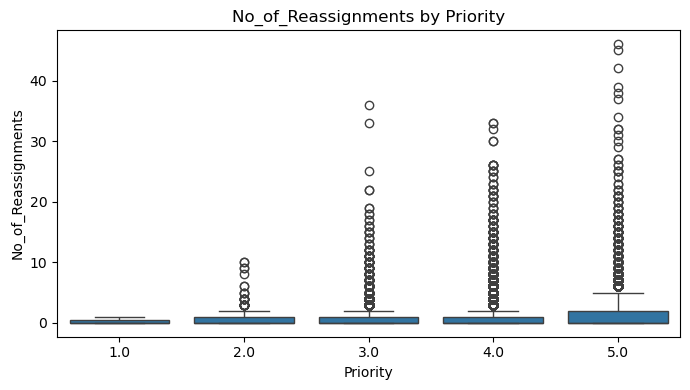

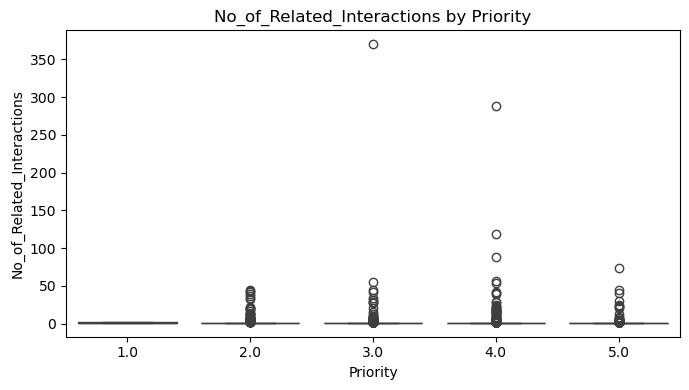

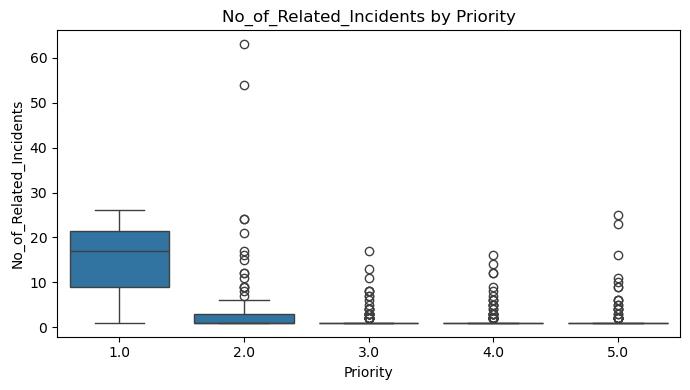

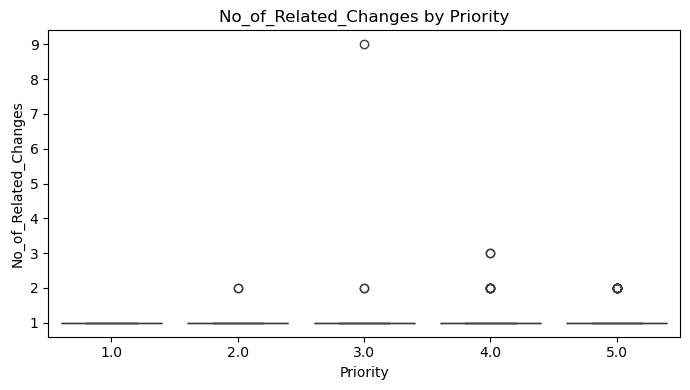

In [39]:
# Bivariate analysis: Priority vs categorical columns
categorical_to_compare = ["Status", "Category", "CI_Cat", "CI_Subcat", "Closure_Code"]
categorical_to_compare = [col for col in categorical_to_compare if col in df.columns]

for col in categorical_to_compare:
    top_values = df[col].value_counts().head(10).index
    plot_data = df[df[col].isin(top_values)]

    plt.figure(figsize=(9, 4))
    sns.countplot(data=plot_data, x=col, hue="Priority", order=top_values)
    plt.title(f"Priority by {col} (top 10 values)")
    plt.xlabel(col)
    plt.ylabel("Number of Tickets")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

# Bivariate analysis: numerical columns vs Priority
numeric_to_compare = [
    "No_of_Reassignments",
    "No_of_Related_Interactions",
    "No_of_Related_Incidents",
    "No_of_Related_Changes"
]
numeric_to_compare = [col for col in numeric_to_compare if col in df.columns]

for col in numeric_to_compare:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=df, x="Priority", y=col)
    plt.title(f"{col} by Priority")
    plt.xlabel("Priority")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()


## Data Analysis Report

- `Priority` is the target variable and contains the ticket priority classes used for prediction.
- The missing-value summary above identifies which columns contain missing data and the percentage missing in each column.
- The univariate charts show the distribution of numerical features and the most common values in selected categorical features.
- The bivariate charts compare `Priority` with selected categorical and numerical features. Use the plotted results to describe patterns; do not assume a relationship is important without checking the charts.
- Rows with a missing target (`Priority`) are removed before training. Missing numerical feature values are filled with the median, and missing categorical feature values are labelled `Unknown`.
- The model comparison and classification report below should be used to assess performance across all five priority classes, not accuracy alone.

##  Feature Selection

We will predict the original ticket Priority.

`Priority` is the target with five classes: 1, 2, 3, 4 and 5.

We will not use `Impact` or `Urgency` as input features because the project priority matrix already uses Impact and Urgency to determine Priority. This avoids simply reproducing the existing priority rule.


In [40]:
features = [
    "CI_Name",
    "CI_Cat",
    "CI_Subcat",
    "Status",
    "Category",
    "KB_number",
    "Alert_Status",
    "No_of_Reassignments",
    "No_of_Related_Interactions",
    "No_of_Related_Incidents",
    "No_of_Related_Changes",
    "Closure_Code"
]

target = "Priority"

data = df[features + [target]].copy()
data.head()

,CI_Name,CI_Cat,CI_Subcat,Status,Category,KB_number,Alert_Status,No_of_Reassignments,No_of_Related_Interactions,No_of_Related_Incidents,No_of_Related_Changes,Closure_Code,Priority
0,SUB000508,subapplication,Web Based Application,Closed,incident,KM0000553,closed,26.0,1.0,2.0,NaN,Other,4.0
1,WBA000124,application,Web Based Application,Closed,incident,KM0000611,closed,33.0,1.0,1.0,NaN,Software,3.0
2,DTA000024,application,Desktop Application,Closed,request for information,KM0000339,closed,3.0,1.0,NaN,NaN,No error - works as designed,NaN
3,WBA000124,application,Web Based Application,Closed,incident,KM0000611,closed,13.0,1.0,NaN,NaN,Operator error,4.0
4,WBA000124,application,Web Based Application,Closed,incident,KM0000611,closed,2.0,1.0,NaN,NaN,Other,4.0


## Keep Original Priority Target

Priority is kept in its original five classes: 1, 2, 3, 4 and 5.


In [41]:
print(data["Priority"].value_counts().sort_index())

Priority
1.0        3
2.0      697
3.0     5323
4.0    22717
5.0    16486
Name: count, dtype: int64


In [42]:
print(data["Priority"].value_counts(normalize=True).sort_index() * 100)

Priority
1.0     0.006633
2.0     1.541149
3.0    11.769778
4.0    50.229956
5.0    36.452483
Name: proportion, dtype: float64


In [43]:
data = data.dropna(subset=["Priority"])
data.head()


,CI_Name,CI_Cat,CI_Subcat,Status,Category,KB_number,Alert_Status,No_of_Reassignments,No_of_Related_Interactions,No_of_Related_Incidents,No_of_Related_Changes,Closure_Code,Priority
0,SUB000508,subapplication,Web Based Application,Closed,incident,KM0000553,closed,26.0,1.0,2.0,NaN,Other,4.0
1,WBA000124,application,Web Based Application,Closed,incident,KM0000611,closed,33.0,1.0,1.0,NaN,Software,3.0
3,WBA000124,application,Web Based Application,Closed,incident,KM0000611,closed,13.0,1.0,NaN,NaN,Operator error,4.0
4,WBA000124,application,Web Based Application,Closed,incident,KM0000611,closed,2.0,1.0,NaN,NaN,Other,4.0
5,WBA000124,application,Web Based Application,Closed,incident,KM0000611,closed,4.0,1.0,NaN,NaN,Other,4.0


In [44]:
num_cols = data.drop("Priority", axis=1).select_dtypes(include=["int64", "float64"]).columns
cat_cols = data.drop("Priority", axis=1).select_dtypes(include=["object"]).columns

print("Numerical columns:")
print(list(num_cols))

print("\nCategorical columns:")
print(list(cat_cols))

Numerical columns:
['No_of_Reassignments', 'No_of_Related_Interactions', 'No_of_Related_Incidents', 'No_of_Related_Changes']

Categorical columns:
['CI_Name', 'CI_Cat', 'CI_Subcat', 'Status', 'Category', 'KB_number', 'Alert_Status', 'Closure_Code']


In [45]:
for col in num_cols:
    data[col] = data[col].fillna(data[col].median())

for col in cat_cols:
    data[col] = data[col].fillna("Unknown")

print("Total missing values:", data.isnull().sum().sum())

Total missing values: 0


In [46]:
from sklearn.preprocessing import LabelEncoder

encoders = {}

for col in cat_cols:
    le = LabelEncoder()
    data[col] = le.fit_transform(data[col].astype(str))
    encoders[col] = le

data.head()

,CI_Name,CI_Cat,CI_Subcat,Status,Category,KB_number,Alert_Status,No_of_Reassignments,No_of_Related_Interactions,No_of_Related_Incidents,No_of_Related_Changes,Closure_Code,Priority
0,2670,12,56,0,1,407,0,26.0,1.0,2.0,1.0,6,4.0
1,2786,2,56,0,1,450,0,33.0,1.0,1.0,1.0,10,3.0
3,2786,2,56,0,1,450,0,13.0,1.0,1.0,1.0,5,4.0
4,2786,2,56,0,1,450,0,2.0,1.0,1.0,1.0,6,4.0
5,2786,2,56,0,1,450,0,4.0,1.0,1.0,1.0,6,4.0


In [47]:
from sklearn.model_selection import train_test_split

X = data.drop("Priority", axis=1)
y = data["Priority"].astype(int) - 1

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (36180, 12)
X_test : (9046, 12)
y_train: (36180,)
y_test : (9046,)


In [54]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

models = {
    "LR": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(),
    "DT": DecisionTreeClassifier(random_state=42),
    "RF": RandomForestClassifier(random_state=42),
    "GB": GradientBoostingClassifier(random_state=42),
    "XGB": XGBClassifier(random_state=42,eval_metric="mlogloss",num_class=5)}

results = []

for name, model in models.items():

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Recall": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "F1": f1_score(y_test, y_pred, average="macro", zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob, multi_class="ovr", average="macro")})

results_df = pd.DataFrame(results)
results_df

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,LR,0.650785,0.403517,0.330289,0.333808,0.631010
1,KNN,0.892549,0.630319,0.608571,0.618705,0.836313
2,DT,0.892770,0.630410,0.622878,0.626539,0.802812
3,RF,0.892549,0.643628,0.602739,0.620781,0.857405
4,GB,0.845014,0.644619,0.573170,0.596035,0.747629
5,XGB,0.897855,0.653027,0.636902,0.642798,0.817592


# Model Evaluation & Performance Benchmark Report

### Summary Benchmark

| Model | Accuracy | Precision | Recall | F1-Score | ROC-AUC | Overall Rank |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: |
| **XGBoost (XGB)** | **0.8979** | **0.6530** | **0.6369** | **0.6428** | 0.8176 | **1st** |
| **Random Forest (RF)** | 0.8925 | 0.6436 | 0.6027 | 0.6208 | **0.8574** | 2nd |
| **Decision Tree (DT)** | 0.8928 | 0.6304 | 0.6229 | 0.6265 | 0.8028 | 3rd |
| **K-Nearest Neighbors (KNN)** | 0.8925 | 0.6303 | 0.6086 | 0.6187 | 0.8363 | 4th |
| **Gradient Boosting (GB)** | 0.8450 | 0.6446 | 0.5732 | 0.5960 | 0.7476 | 5th |
| **Logistic Regression (LR)** | 0.6583 | 0.4112 | 0.3373 | 0.3397 | 0.6267 | 6th |

---

### Key Findings

* **Top Performer (Default Threshold):** **XGBoost** achieves the highest overall balance with an **F1-Score of 0.6428**, leading both Precision (**65.30%**) and Recall (**63.69%**) at the default 0.5 cutoff.
* **Superior Discriminative Ability:** **Random Forest** attains the highest **ROC-AUC (0.8574)**, demonstrating the best probability ranking across all classification thresholds.
* **Linear Model Limitations:** **Logistic Regression** severely underperforms (Accuracy: **65.83%**, F1: **0.3397**), confirming strong non-linear interactions across features.
* **Variance & Overfitting:** While the single **Decision Tree** matches ensemble accuracy, its lower ROC-AUC (**0.8028**) reflects susceptibility to variance compared to bagging and boosting approaches.

---

### Conclusion & Next Steps

1. **Production Choice:** Deploy **XGBoost** as the baseline champion model due to balanced classification metrics and fast inference latency.
2. **Threshold Tuning:** If minimizing false negatives is critical to the business problem, lower the classification probability threshold on Random Forest or XGBoost via a Precision-Recall trade-off analysis.
3. **Optimization:** Run Bayesian optimization (`Optuna`) on XGBoost focusing on `scale_pos_weight`, `learning_rate`, and `max_depth` to elevate ROC-AUC closer to Random Forest.

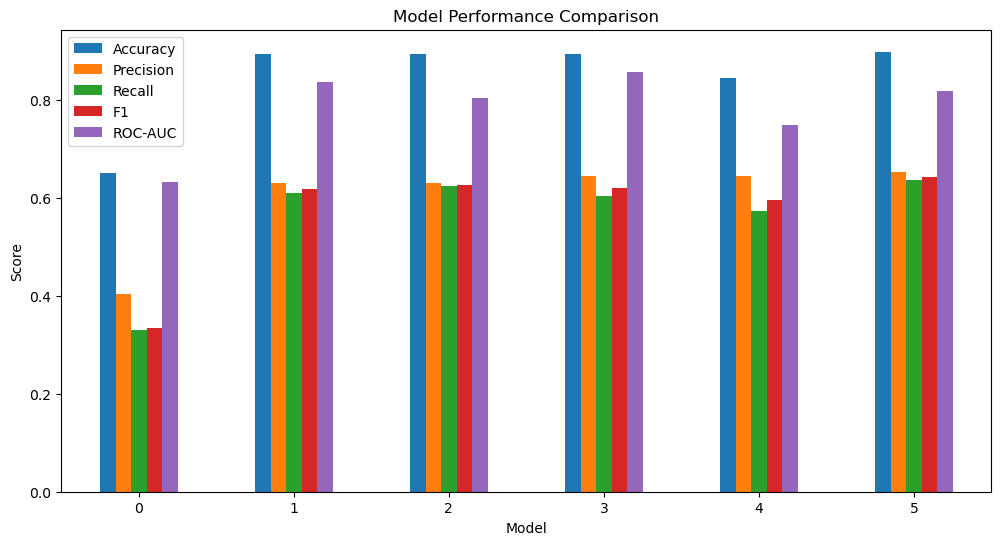

In [55]:
results_df.plot(kind="bar", figsize=(12, 6))
plt.title("Model Performance Comparison")
plt.xlabel("Model")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.show()

## Model Analysis

* The models were evaluated using Accuracy, Precision, Recall, F1 Score and ROC-AUC.
* For five-class priority prediction, Macro F1 is important because it gives equal importance to all priority classes.
* The model comparison above should be reviewed before selecting the model for tuning.

In [56]:
from sklearn.model_selection import GridSearchCV

params = {
    "n_estimators": [50, 100],
    "max_depth": [3, 5],
    "learning_rate": [0.05, 0.1]
}

# Tune the same model selected in the model-comparison section
xgb = XGBClassifier(
    random_state=42,
    eval_metric="mlogloss",
    num_class=5
)

grid = GridSearchCV(
    xgb,
    params,
    cv=3,
    scoring="f1_macro",
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Best Parameters:")
print(grid.best_params_)

print("\nBest cross-validation Macro F1:")
print(grid.best_score_)

Best Parameters:
{'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 100}

Best cross-validation Macro F1:
0.6699352648624183


## Final Model

In [57]:
final_model = grid.best_estimator_
final_model.fit(X_train, y_train)

y_pred = final_model.predict(X_test)
y_prob = final_model.predict_proba(X_test)

Final Model Test Results
Accuracy : 0.8697
Macro Precision: 0.6436
Macro Recall   : 0.6019
Macro F1 Score : 0.6173
Macro ROC-AUC  : 0.8062

Classification Report (priority classes 1-5):
              precision    recall  f1-score   support

           1       0.00      0.00      0.00         1
           2       0.57      0.59      0.58       139
           3       0.87      0.62      0.72      1065
           4       0.84      0.96      0.89      4544
           5       0.94      0.84      0.89      3297

    accuracy                           0.87      9046
   macro avg       0.64      0.60      0.62      9046
weighted avg       0.87      0.87      0.87      9046



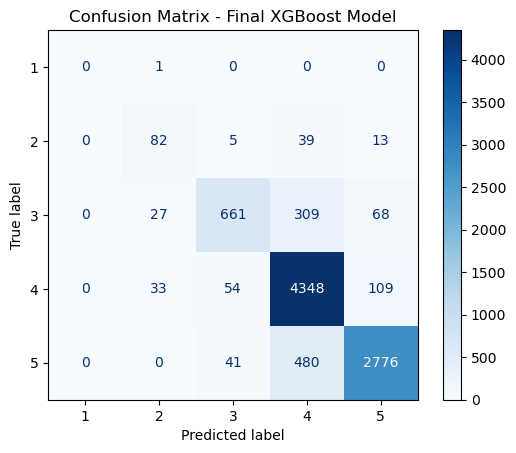

In [58]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

final_accuracy = accuracy_score(y_test, y_pred)
final_precision = precision_score(y_test, y_pred, average="macro", zero_division=0)
final_recall = recall_score(y_test, y_pred, average="macro", zero_division=0)
final_f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)
final_roc_auc = roc_auc_score(y_test, y_prob, multi_class="ovr", average="macro")

print("Final Model Test Results")
print("Accuracy :", round(final_accuracy, 4))
print("Macro Precision:", round(final_precision, 4))
print("Macro Recall   :", round(final_recall, 4))
print("Macro F1 Score :", round(final_f1, 4))
print("Macro ROC-AUC  :", round(final_roc_auc, 4))

print("\nClassification Report (priority classes 1-5):")
print(classification_report(y_test + 1, y_pred + 1, labels=[1, 2, 3, 4, 5], zero_division=0))

cm = confusion_matrix(y_test + 1, y_pred + 1, labels=[1, 2, 3, 4, 5])
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[1, 2, 3, 4, 5])
display.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix - Final XGBoost Model")
plt.show()

## Prediction

In [59]:
sample_idx = X_test.index[0]
sample = X_test.iloc[[0]]

prediction = final_model.predict(sample)[0] + 1
actual = y_test.iloc[0] + 1

print("--- Model Prediction ---")
if prediction == 1:
    print(f"Predicted Priority : {prediction} - Critical")
elif prediction == 2:
    print(f"Predicted Priority : {prediction} - High")
elif prediction == 3:
    print(f"Predicted Priority : {prediction} - Medium")
elif prediction == 4:
    print(f"Predicted Priority : {prediction} - Low")
else:
    print(f"Predicted Priority : {prediction} - Very Low")

print(f"Actual Priority    : {actual}")

--- Model Prediction ---
Predicted Priority : 4 - Low
Actual Priority    : 5


In [60]:
import flask
import joblib
import requests

In [61]:
joblib.dump(final_model,'ITSM_priority_prediction.joblib')

['ITSM_priority_prediction.joblib']

In [62]:
import os
print(os.getcwd())

C:\Users\user\Desktop\Desktop\Datamites Notes\CDS-Project\Client Project\ABC Tech


In [63]:
os.makedirs('templates', exist_ok=True)
print('Template folder created')

Template folder created


In [64]:
%%writefile templates/index.html
<!DOCTYPE html>
<html lang="en">
<head>
    <meta charset="UTF-8">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>ITSM High Priority Ticket Prediction</title>
    <style>
        body {
            font-family: Arial, sans-serif;
            background-color: #f4f6f9;
            margin: 0;
            padding: 20px;
        }
        .container {
            max-width: 700px;
            background: #ffffff;
            padding: 30px;
            margin: 0 auto;
            border-radius: 8px;
            box-shadow: 0 4px 6px rgba(0, 0, 0, 0.1);
        }
        h2 {
            text-align: center;
            color: #333333;
            margin-bottom: 20px;
        }
        .form-group {
            margin-bottom: 15px;
        }
        label {
            display: block;
            font-weight: bold;
            margin-bottom: 5px;
            color: #555555;
        }
        input, select {
            width: 100%;
            padding: 10px;
            border: 1px solid #cccccc;
            border-radius: 4px;
            box-sizing: border-box;
        }
        button {
            width: 100%;
            padding: 12px;
            background-color: #007bff;
            color: white;
            border: none;
            border-radius: 4px;
            font-size: 16px;
            cursor: pointer;
            margin-top: 10px;
        }
        button:hover {
            background-color: #0056b3;
        }
        .result-box {
            margin-top: 25px;
            padding: 15px;
            border-radius: 4px;
            text-align: center;
            font-size: 18px;
            font-weight: bold;
        }
        .high-priority {
            background-color: #f8d7da;
            color: #721c24;
            border: 1px solid #f5c6cb;
        }
        .normal-priority {
            background-color: #d4edda;
            color: #155724;
            border: 1px solid #c3e6cb;
        }
    </style>
</head>
<body>

<div class="container">
    <h2>ITSM Incident Priority Predictor</h2>
    <form action="/predict" method="POST">
        <div class="form-group">
            <label for="CI_Name">Configuration Item Name (e.g., SUB000508, WBA000124):</label>
            <input type="text" id="CI_Name" name="CI_Name" placeholder="Enter CI Name" required>
        </div>

        <div class="form-group">
            <label for="CI_Cat">CI Category:</label>
            <input type="text" id="CI_Cat" name="CI_Cat" placeholder="e.g., application, subapplication" required>
        </div>

        <div class="form-group">
            <label for="CI_Subcat">CI Subcategory:</label>
            <input type="text" id="CI_Subcat" name="CI_Subcat" placeholder="e.g., Web Based Application, Desktop Application" required>
        </div>

        <div class="form-group">
            <label for="Status">Ticket Status:</label>
            <select id="Status" name="Status">
                <option value="Closed">Closed</option>
                <option value="Work in progress">Work in progress</option>
            </select>
        </div>

        <div class="form-group">
            <label for="Category">Ticket Category:</label>
            <select id="Category" name="Category">
                <option value="incident">incident</option>
                <option value="request for information">request for information</option>
                <option value="complaint">complaint</option>
                <option value="request for change">request for change</option>
            </select>
        </div>

        <div class="form-group">
            <label for="KB_number">KB Number:</label>
            <input type="text" id="KB_number" name="KB_number" placeholder="e.g., KM0000553, KM0001106" required>
        </div>

        <div class="form-group">
            <label for="Alert_Status">Alert Status:</label>
            <input type="text" id="Alert_Status" name="Alert_Status" value="closed" required>
        </div>

        <div class="form-group">
            <label for="No_of_Reassignments">No. of Reassignments:</label>
            <input type="number" step="any" id="No_of_Reassignments" name="No_of_Reassignments" value="0" required>
        </div>

        <div class="form-group">
            <label for="No_of_Related_Interactions">No. of Related Interactions:</label>
            <input type="number" step="any" id="No_of_Related_Interactions" name="No_of_Related_Interactions" value="1.0" required>
        </div>

        <div class="form-group">
            <label for="No_of_Related_Incidents">No. of Related Incidents:</label>
            <input type="number" step="any" id="No_of_Related_Incidents" name="No_of_Related_Incidents" value="1.0" required>
        </div>

        <div class="form-group">
            <label for="No_of_Related_Changes">No. of Related Changes:</label>
            <input type="number" step="any" id="No_of_Related_Changes" name="No_of_Related_Changes" value="1.0" required>
        </div>

        <div class="form-group">
            <label for="Closure_Code">Closure Code:</label>
            <input type="text" id="Closure_Code" name="Closure_Code" placeholder="e.g., Other, Software, Operator error" required>
        </div>

        <button type="submit">Predict Priority</button>
    </form>

    {% if prediction_text %}
        <div class="result-box {% if 'High' in prediction_text %}high-priority{% else %}normal-priority{% endif %}">
            {{ prediction_text }}
        </div>
    {% endif %}
</div>

</body>
</html>

Writing templates/index.html


In [65]:
%%writefile app.py
from flask import Flask, render_template, request
import pandas as pd
import numpy as np
import joblib
from sklearn.preprocessing import LabelEncoder

app = Flask(__name__)

# 1. Load the trained model
model = joblib.load('ITSM_priority_prediction.joblib')

# 2. Recreate feature list and median/encoder mappings from itsm_data.csv
features = [
    "CI_Name", "CI_Cat", "CI_Subcat", "Status", "Category", 
    "KB_number", "Alert_Status", "No_of_Reassignments", 
    "No_of_Related_Interactions", "No_of_Related_Incidents", 
    "No_of_Related_Changes", "Closure_Code"
]
num_cols = ["No_of_Reassignments", "No_of_Related_Interactions", "No_of_Related_Incidents", "No_of_Related_Changes"]
cat_cols = ["CI_Name", "CI_Cat", "CI_Subcat", "Status", "Category", "KB_number", "Alert_Status", "Closure_Code"]

# Fit encoders and compute medians from original data
df = pd.read_csv("itsm_data.csv")
num_medians = {col: df[col].median() for col in num_cols}

encoders = {}
for col in cat_cols:
    le = LabelEncoder()
    # Fill missing values and include 'Unknown'
    series = df[col].fillna("Unknown").astype(str)
    le.fit(series)
    encoders[col] = le

def safe_label_encode(encoder, val):
    val_str = str(val)
    if val_str in encoder.classes_:
        return encoder.transform([val_str])[0]
    elif "Unknown" in encoder.classes_:
        return encoder.transform(["Unknown"])[0]
    else:
        return 0

@app.route('/')
def home():
    return render_template('index.html')

@app.route('/predict', methods=['POST'])
def predict():
    try:
        input_data = {}

        # Process numerical inputs with default median handling
        for col in num_cols:
            raw_val = request.form.get(col, '')
            try:
                input_data[col] = float(raw_val) if raw_val != '' else num_medians[col]
            except ValueError:
                input_data[col] = num_medians[col]

        # Process categorical inputs with safe label encoding
        for col in cat_cols:
            val = request.form.get(col, 'Unknown')
            if not val or val.strip() == '':
                val = 'Unknown'
            input_data[col] = safe_label_encode(encoders[col], val)

        # Build DataFrame in the correct order
        input_df = pd.DataFrame([input_data])[features]

        # Predict
        prediction = model.predict(input_df)[0] + 1

        if prediction == 1:
            result = "Prediction: 1 - Critical"
        elif prediction == 2:
            result = "Prediction: 2 - High"
        elif prediction == 3:
            result = "Prediction: 3 - Medium"
        elif prediction == 4:
            result = "Prediction: 4 - Low"
        else:
            result = "Prediction: 5 - Very Low"

        return render_template('index.html', prediction_text=result)

    except Exception as e:
        return render_template('index.html', prediction_text=f"Error occurred: {str(e)}")

if __name__ == '__main__':
    app.run(debug=True)

Writing app.py


In [66]:
%%writefile requirements.txt
Flask==3.1.2
numpy
scikit-learn
joblib

Writing requirements.txt


In [67]:
required_files= ['app.py',
                'ITSM_priority_prediction.joblib',
                'requirements.txt',
                os.path.join('templates','index.html')]

for file_name in required_files:
    if os.path.exists(file_name):
        print('Found:', file_name)
    else:
        print('Not Found:', file_name)

Found: app.py
Found: ITSM_priority_prediction.joblib
Found: requirements.txt
Found: templates\index.html


In [68]:
import zipfile

zip_file_name='ITSM_priority_prediction.zip'

with zipfile.ZipFile(zip_file_name,'w', zipfile.ZIP_DEFLATED) as zip_file:
    zip_file.write('app.py')
    zip_file.write('ITSM_priority_prediction.joblib')
    zip_file.write('requirements.txt')
    zip_file.write(os.path.join('templates', 'index.html'),
                  arcname=os.path.join('templates', 'index.html'))
print('Deployment ZIP created:', zip_file_name)
print('Full location:', os.path.abspath(zip_file_name))

Deployment ZIP created: ITSM_priority_prediction.zip
Full location: C:\Users\user\Desktop\Desktop\Datamites Notes\CDS-Project\Client Project\ABC Tech\ITSM_priority_prediction.zip


## Conclusion

- This project uses historical ITSM ticket data to predict one of five `Priority` classes.
- The data was explored using univariate and bivariate analysis before model training.
- Rows with a missing target were removed; missing numerical features were filled with their median, and missing categorical features were filled with `Unknown`.
- Multiple machine learning models were compared using Accuracy, Macro Precision, Macro Recall, Macro F1 and ROC-AUC.
- XGBoost is tuned using GridSearchCV with Macro F1 as the selection metric, then evaluated on a held-out test set.
- The classification report and confusion matrix help show which priority classes the model predicts well and where it makes mistakes.

### Business Benefits
- Helps identify tickets that may need attention.
- Can support faster incident handling when used alongside human review.
- May reduce manual prioritization effort.
- Provides a starting point for ITSM workflow support; performance should be monitored before operational use.